<a href="https://colab.research.google.com/github/Jamieho1602/IBM-HR-Analytics-Overview/blob/main/IBM_HR_Analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**IBM HR Analytics: Employee Attrition and Retention**

**Objective:** Identify factors associated with attrition and recommend a Total Rewards retention strategy.


## 1. Data Preparation
Load, check and clean the five datasets.


In [12]:
# Load the five IBM HR Analytics datasets from GitHub
import pandas as pd

employees = pd.read_csv('https://raw.githubusercontent.com/Jamieho1602/IBM-HR-Analytics-Overview/refs/heads/main/Employees.csv')

compensation = pd.read_csv('https://raw.githubusercontent.com/Jamieho1602/IBM-HR-Analytics-Overview/refs/heads/main/Compensation.csv')

performance = pd.read_csv('https://raw.githubusercontent.com/Jamieho1602/IBM-HR-Analytics-Overview/refs/heads/main/Performance.csv')

experience = pd.read_csv('https://raw.githubusercontent.com/Jamieho1602/IBM-HR-Analytics-Overview/refs/heads/main/Experience.csv')

employment_status = pd.read_csv('https://raw.githubusercontent.com/Jamieho1602/IBM-HR-Analytics-Overview/refs/heads/main/Employment%20Status.csv')

# Check the number of rows and columns
print(employees.shape)
print(compensation.shape)
print(performance.shape)
print(experience.shape)
print(employment_status.shape)

(1470, 14)
(1470, 7)
(1470, 7)
(1470, 8)
(1470, 3)


In [13]:
##Check for missing values.
print("Employees Missing Values")
print(employees.isnull().sum())

print("Compensation Missing Values")
print(compensation.isnull().sum())

print("Performance Missing Values")
print(performance.isnull().sum())

print("Experience Missing Values")
print(experience.isnull().sum())

print("Employment Status Missing Values")
print(employment_status.isnull().sum())


Employees Missing Values
EmployeeNumber      0
Age                 5
Gender              0
MaritalStatus       0
Education           0
EducationField      0
Department          0
JobRole             0
JobLevel            0
BusinessTravel      0
DistanceFromHome    0
EmployeeCount       0
Over18              0
StandardHours       0
dtype: int64
Compensation Missing Values
EmployeeNumber       0
DailyRate            0
HourlyRate           0
MonthlyIncome        0
MonthlyRate          0
PercentSalaryHike    0
StockOptionLevel     0
dtype: int64
Performance Missing Values
EmployeeNumber              0
PerformanceRating           0
EnvironmentSatisfaction     0
JobInvolvement              0
JobSatisfaction             0
RelationshipSatisfaction    0
WorkLifeBalance             0
dtype: int64
Experience Missing Values
EmployeeNumber             0
NumCompaniesWorked         0
TotalWorkingYears          0
TrainingTimesLastYear      0
YearsAtCompany             0
YearsInCurrentRole         0
Ye

In [14]:
employees[employees['Age'].isnull()]

,EmployeeNumber,Age,Gender,MaritalStatus,Education,EducationField,Department,JobRole,JobLevel,BusinessTravel,DistanceFromHome,EmployeeCount,Over18,StandardHours
5,8,NaN,Male,Single,2,Life Sciences,Research & Development,Laboratory Technician,1,Travel_Frequently,2,1,Y,80
27,35,NaN,Male,Married,4,Marketing,Sales,Sales Executive,2,Travel_Rarely,8,1,Y,80
134,177,NaN,Female,Married,1,Life Sciences,Human Resources,Human Resources,1,Travel_Rarely,25,1,Y,80
262,362,NaN,Male,Single,1,Technical Degree,Research & Development,Laboratory Technician,2,Travel_Rarely,2,1,Y,80
377,501,NaN,Female,Married,3,Life Sciences,Research & Development,Research Scientist,1,Travel_Rarely,2,1,Y,80


In [15]:
##Remove the 5 employees with missing 'Age' from the datasets.  5 out of 1470 employees will not caused an significant
##impact on the analysis.
employees = employees.dropna(subset=['Age'])

employees.shape


(1465, 14)

In [18]:
compensation = compensation[compensation['EmployeeNumber'].isin(employees['EmployeeNumber'])]

performance = performance[performance['EmployeeNumber'].isin(employees['EmployeeNumber'])]

experience = experience[experience['EmployeeNumber'].isin(employees['EmployeeNumber'])]

employment_status = employment_status[employment_status['EmployeeNumber'].isin(employees['EmployeeNumber'])]


In [19]:
print("Employees:", employees.shape)
print("Compensation:", compensation.shape)
print("Performance:", performance.shape)
print("Experience:", experience.shape)
print("Employment Status:", employment_status.shape)

Employees: (1465, 14)
Compensation: (1465, 7)
Performance: (1465, 7)
Experience: (1465, 8)
Employment Status: (1465, 3)


## 2. Exploratory Data Analysis (EDA)
Brief checks of the five datasets.


### Employees


In [20]:
 ##EDA : Explore the Employees Dataset

print("Dataset Shape:")
print(employees.shape)

print("\nColumn Names:")
print(employees.columns)

print("\nMissing Values:")
print(employees.isnull().sum())

print("\nFirst 5 Records:")
print(employees.head())


Dataset Shape:
(1465, 14)

Column Names:
Index(['EmployeeNumber', 'Age', 'Gender', 'MaritalStatus', 'Education',
       'EducationField', 'Department', 'JobRole', 'JobLevel', 'BusinessTravel',
       'DistanceFromHome', 'EmployeeCount', 'Over18', 'StandardHours'],
      dtype='object')

Missing Values:
EmployeeNumber      0
Age                 0
Gender              0
MaritalStatus       0
Education           0
EducationField      0
Department          0
JobRole             0
JobLevel            0
BusinessTravel      0
DistanceFromHome    0
EmployeeCount       0
Over18              0
StandardHours       0
dtype: int64

First 5 Records:
   EmployeeNumber   Age  Gender MaritalStatus  Education EducationField  \
0               1  41.0  Female        Single          2  Life Sciences   
1               2  49.0    Male       Married          1  Life Sciences   
2               4  37.0    Male        Single          2          Other   
3               5  33.0  Female       Married          4 

In [21]:

# EDA 1.2: Employee Age Distribution

print("Age Summary:")
print(employees['Age'].describe())


Age Summary:
count    1465.000000
mean       36.935154
std         9.143694
min        18.000000
25%        30.000000
50%        36.000000
75%        43.000000
max        60.000000
Name: Age, dtype: float64


In [22]:
# Standardise gender labels in Employees Dataset

employees['Gender'] = employees['Gender'].str.strip()

employees['Gender'] = employees['Gender'].replace({
    'Femal': 'Female',
    'M': 'Male',
    'm': 'Male'
})

print(employees['Gender'].value_counts())


Gender
Male      879
Female    586
Name: count, dtype: int64


In [23]:
# EDA 1: Workforce Composition

print("Gender Distribution:")
print(employees['Gender'].value_counts())

print("\nDepartment Distribution:")
print(employees['Department'].value_counts())

print("\nJob Level Distribution:")
print(employees['JobLevel'].value_counts())

Gender Distribution:
Gender
Male      879
Female    586
Name: count, dtype: int64

Department Distribution:
Department
Research & Development    958
Sales                     445
Human Resources            62
Name: count, dtype: int64

Job Level Distribution:
JobLevel
1    540
2    532
3    218
4    106
5     69
Name: count, dtype: int64


### Compensation


In [27]:

# EDA 2: Compensation Dataset

print("Dataset Shape:")
print(compensation.shape)

print("\nMonthly Income Summary:")
print(compensation['MonthlyIncome'].describe().round(2))

print("\nStock Option Distribution:")
print(compensation['StockOptionLevel'].value_counts())


Dataset Shape:
(1465, 7)

Monthly Income Summary:
count     1465.00
mean      6513.14
std       4711.70
min       1009.00
25%       2911.00
50%       4936.00
75%       8381.00
max      19999.00
Name: MonthlyIncome, dtype: float64

Stock Option Distribution:
StockOptionLevel
0    629
1    593
2    158
3     85
Name: count, dtype: int64


### Performance


In [28]:
# EDA 3: Performance Dataset

print("Dataset Shape:")
print(performance.shape)

print("\nColumn Names:")
print(performance.columns)

print("\nMissing Values:")
print(performance.isnull().sum())

print("\nFirst 5 Records:")
print(performance.head())

Dataset Shape:
(1465, 7)

Column Names:
Index(['EmployeeNumber', 'PerformanceRating', 'EnvironmentSatisfaction',
       'JobInvolvement', 'JobSatisfaction', 'RelationshipSatisfaction',
       'WorkLifeBalance'],
      dtype='object')

Missing Values:
EmployeeNumber              0
PerformanceRating           0
EnvironmentSatisfaction     0
JobInvolvement              0
JobSatisfaction             0
RelationshipSatisfaction    0
WorkLifeBalance             0
dtype: int64

First 5 Records:
   EmployeeNumber  PerformanceRating  EnvironmentSatisfaction  JobInvolvement  \
0               1                  3                        2               3   
1               2                  4                        3               2   
2               4                  3                        4               2   
3               5                  3                        4               3   
4               7                  3                        1               3   

   JobSatisfaction  R

### Experience


In [29]:
# EDA 4: Experience Dataset
print("Dataset Shape:")
print(experience.shape)
print("\nColumn Names:")
print(experience.columns)
print("\nMissing Values:")
print(experience.isnull().sum())
print("\nFirst 5 Records:")
print(experience.head())


Dataset Shape:
(1465, 8)

Column Names:
Index(['EmployeeNumber', 'NumCompaniesWorked', 'TotalWorkingYears',
       'TrainingTimesLastYear', 'YearsAtCompany', 'YearsInCurrentRole',
       'YearsSinceLastPromotion', 'YearsWithCurrManager'],
      dtype='object')

Missing Values:
EmployeeNumber             0
NumCompaniesWorked         0
TotalWorkingYears          0
TrainingTimesLastYear      0
YearsAtCompany             0
YearsInCurrentRole         0
YearsSinceLastPromotion    0
YearsWithCurrManager       0
dtype: int64

First 5 Records:
   EmployeeNumber  NumCompaniesWorked  TotalWorkingYears  \
0               1                   8                  8   
1               2                   1                 10   
2               4                   6                  7   
3               5                   1                  8   
4               7                   9                  6   

   TrainingTimesLastYear  YearsAtCompany  YearsInCurrentRole  \
0                      0          

### Employment Status


In [30]:
# EDA 5: Employment Status Dataset

print("Dataset Shape:")
print(employment_status.shape)

print("\nColumn Names:")
print(employment_status.columns)

print("\nMissing Values:")
print(employment_status.isnull().sum())

print("\nFirst 5 Records:")
print(employment_status.head())

print("\nAttrition Distribution:")
print(employment_status['Attrition'].value_counts())

print("\nOvertime Distribution:")
print(employment_status['OverTime'].value_counts())

Dataset Shape:
(1465, 3)

Column Names:
Index(['EmployeeNumber', 'Attrition', 'OverTime'], dtype='object')

Missing Values:
EmployeeNumber    0
Attrition         0
OverTime          0
dtype: int64

First 5 Records:
   EmployeeNumber Attrition OverTime
0               1       Yes      Yes
1               2        No       No
2               4       Yes      Yes
3               5        No      Yes
4               7        No       No

Attrition Distribution:
Attrition
No     1228
Yes     237
Name: count, dtype: int64

Overtime Distribution:
OverTime
No     1049
Yes     416
Name: count, dtype: int64


## 3. Merge Datasets and Final Checks


In [31]:
hr_data = pd.merge(employees, compensation, on='EmployeeNumber')

hr_data.shape


(1465, 20)

In [32]:

hr_data = pd.merge(hr_data, performance, on='EmployeeNumber')
hr_data = pd.merge(hr_data, experience, on='EmployeeNumber')
hr_data = pd.merge(hr_data, employment_status, on='EmployeeNumber')

hr_data.shape

(1465, 35)

In [33]:
hr_data['Attrition_Flag'] = (hr_data['Attrition'] == 'Yes') * 1

In [34]:
# Check categorical columns for inconsistent values

for column in ['Gender', 'MaritalStatus', 'EducationField',
               'Department', 'JobRole', 'BusinessTravel',
               'Attrition', 'OverTime']:
    print(column)
    print(hr_data[column].value_counts())
    print("--------------------")


Gender
Gender
Male      879
Female    586
Name: count, dtype: int64
--------------------
MaritalStatus
MaritalStatus
Married     670
Single      468
Divorced    327
Name: count, dtype: int64
--------------------
EducationField
EducationField
Life Sciences       603
Medical             464
Marketing           158
Technical Degree    131
Other                82
Human Resources      27
Name: count, dtype: int64
--------------------
Department
Department
Research & Development    958
Sales                     445
Human Resources            62
Name: count, dtype: int64
--------------------
JobRole
JobRole
Sales Executive              325
Research Scientist           291
Laboratory Technician        257
Manufacturing Director       145
Healthcare Representative    131
Manager                      102
Sales Representative          83
Research Director             80
Human Resources               51
Name: count, dtype: int64
--------------------
BusinessTravel
BusinessTravel
Travel_Rarely     

In [35]:
# Remove extra spaces
hr_data['Gender'] = hr_data['Gender'].str.strip()

# Correct inconsistent entries
hr_data['Gender'] = hr_data['Gender'].replace({
    'Femal': 'Female',
    'M': 'Male',
    'm': 'Male'
})

# Check results
print(hr_data['Gender'].value_counts())

Gender
Male      879
Female    586
Name: count, dtype: int64


## 4. Research Questions


In [36]:
import matplotlib.pyplot as plt

### RQ1. Which departments and job roles have the highest attrition rates?
**Workforce patterns:** department, job role and job level.


In [37]:
hr_data.groupby('Department')['Attrition'].value_counts()

Department              Attrition
Human Resources         No            50
                        Yes           12
Research & Development  No           825
                        Yes          133
Sales                   No           353
                        Yes           92
Name: count, dtype: int64

In [39]:
##Research Question 1.1
##Calculate attrition rate by department

(hr_data.groupby('Department')['Attrition_Flag'].mean() * 100).round(2)


,Attrition_Flag
Department,
Human Resources,19.35
Research & Development,13.88
Sales,20.67


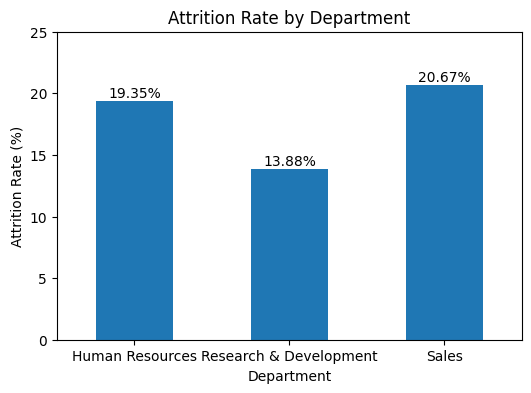

In [99]:
import matplotlib.pyplot as plt

department_attrition = hr_data.groupby('Department')['Attrition_Flag'].mean() * 100

ax = department_attrition.plot(
    kind='bar',
    figsize=(6, 4),
    title='Attrition Rate by Department'
)

for i, value in enumerate(department_attrition):
    plt.text(i, value + 0.3, f'{value:.2f}%', ha='center')

plt.ylabel('Attrition Rate (%)')
plt.xlabel('Department')
plt.xticks(rotation=0)
plt.ylim(0, 25)
plt.show()

Observations – Attrition Rate by Department

Sales has the highest attrition rate at 20.67%, followed by Human Resources at 19.35%.

Research & Development has the lowest attrition rate at 13.88%.

The difference between Sales and Research & Development is 6.79%. This indicate that attrition varies across departments.

Conclusion: Sales and Human Resources have higher attrition rates and should be prioritised for further investigation to identify possible retention challenges.

In [40]:
##To calculate job role attrition rate by numbers
hr_data.groupby('JobRole')['Attrition'].value_counts()


JobRole                    Attrition
Healthcare Representative  No           122
                           Yes            9
Human Resources            No            39
                           Yes           12
Laboratory Technician      No           195
                           Yes           62
Manager                    No            97
                           Yes            5
Manufacturing Director     No           135
                           Yes           10
Research Director          No            78
                           Yes            2
Research Scientist         No           244
                           Yes           47
Sales Executive            No           268
                           Yes           57
Sales Representative       No            50
                           Yes           33
Name: count, dtype: int64

In [41]:
## To calculate job role attrition rate by percentage.


(hr_data.groupby('JobRole')['Attrition_Flag'].mean() * 100).sort_values(ascending=False).round(2)

,Attrition_Flag
JobRole,
Sales Representative,39.76
Laboratory Technician,24.12
Human Resources,23.53
Sales Executive,17.54
Research Scientist,16.15
Manufacturing Director,6.90
Healthcare Representative,6.87
Manager,4.90
Research Director,2.50


In [42]:
hr_data[hr_data['Attrition'] == 'Yes'].groupby(['Department', 'JobRole'])['Attrition'].value_counts()


Department              JobRole                    Attrition
Human Resources         Human Resources            Yes          12
Research & Development  Healthcare Representative  Yes           9
                        Laboratory Technician      Yes          62
                        Manager                    Yes           3
                        Manufacturing Director     Yes          10
                        Research Director          Yes           2
                        Research Scientist         Yes          47
Sales                   Manager                    Yes           2
                        Sales Executive            Yes          57
                        Sales Representative       Yes          33
Name: count, dtype: int64

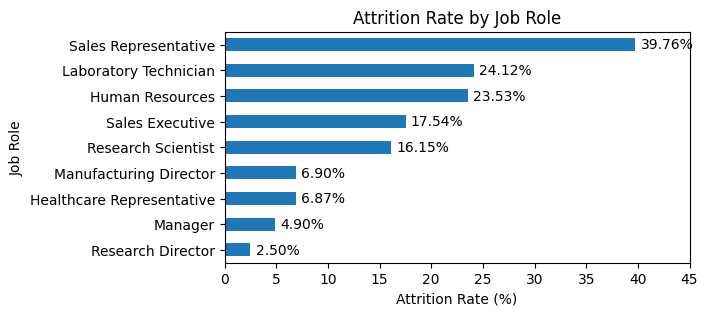

In [43]:
job_attrition = hr_data.groupby('JobRole')['Attrition_Flag'].mean() * 100
job_attrition = job_attrition.sort_values()

ax = job_attrition.plot(
    kind='barh',
    figsize=(6, 3),
    title='Attrition Rate by Job Role'
)

for i, value in enumerate(job_attrition):
    plt.text(value + 0.5, i, f'{value:.2f}%', va='center')

plt.xlabel('Attrition Rate (%)')
plt.ylabel('Job Role')
plt.xlim(0, 45)
plt.show()

Observations – Attrition Rate by Job Role

Sales Representatives has the highest attrition rate at 39.76%,

This is followed by Laboratory Technicians at 24.12% and Human Resources at 23.53%.

Attrition rate for Research Directors is 2.50% and Managers
4.90%; the lowest attrition rates.

The findings indicates that attrition varies across different job roles, with some operational and frontline positions experiencing higher turnover than managerial positions.

Conclusion: HR should consider adopting a holistic Total Rewards framework to address employee retention challenges, taking into account both financial and non-financial factors that may influence employee attrition.

In [44]:
(hr_data.groupby('JobLevel')['Attrition_Flag'].mean() * 100).sort_values(ascending=False).round(2)

,Attrition_Flag
JobLevel,
1,26.48
3,14.68
2,9.77
5,7.25
4,4.72


**Travel and commute:** business travel and distance from home.


In [45]:
# Research Question 1.5
# Is the frequency of business travel associated with employee attrition?

(hr_data.groupby('BusinessTravel')['Attrition_Flag'].mean() * 100).sort_values(ascending=False).round(2)

,Attrition_Flag
BusinessTravel,
Travel_Frequently,25.00
Travel_Rarely,15.01
Non-Travel,8.00


In [46]:
# Research Question 1.6
# Are employees who live farther from the workplace more likely to leave?

hr_data.groupby('Attrition')['DistanceFromHome'].mean().round(2)


,DistanceFromHome
Attrition,
No,8.92
Yes,10.63


In [47]:
# Research Question 1.7 Step 1
# Business travel frequency and attrition across departments

(hr_data.groupby(['Department', 'BusinessTravel'])['Attrition_Flag'].mean() * 100).round(2)


Department              BusinessTravel   
Human Resources         Non-Travel            0.00
                        Travel_Frequently    36.36
                        Travel_Rarely        17.78
Research & Development  Non-Travel            8.25
                        Travel_Frequently    20.44
                        Travel_Rarely        12.94
Sales                   Non-Travel            8.51
                        Travel_Frequently    33.33
                        Travel_Rarely        19.11
Name: Attrition_Flag, dtype: float64

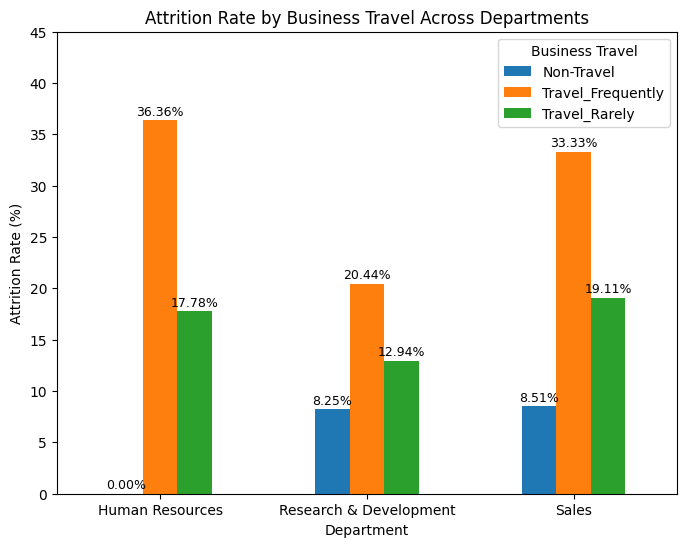

In [48]:
travel_dept = hr_data.groupby(
    ['Department', 'BusinessTravel']
)['Attrition_Flag'].mean() * 100

travel_dept = travel_dept.unstack()

ax = travel_dept.plot(
    kind='bar',
    figsize=(8, 6),
    title='Attrition Rate by Business Travel Across Departments'
)

# Display percentage above each bar
for bar in ax.patches:
    height = bar.get_height()
    if height == height:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.5,
            f'{height:.2f}%',
            ha='center',
            fontsize=9
        )

plt.xlabel('Department')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=0)
plt.legend(title='Business Travel')
plt.ylim(0, 45)
plt.show()


Observations – Attrition Rate by Business Travel Across Departments

Employees who travel frequently recorded the highest attrition rates across all three departments.

Human Resources has the highest attrition rate among frequent travellers at 36.36%, followed by Sales at 33.33% and Research & Development at 20.44%.

Employees who do not travel generally has the lowest attrition rates, with 0% in Human Resources, 8.25% in Research & Development and 8.51% in Sales.

The consistent pattern suggests that frequent business travel is associated with higher employee attrition.

Conclusion:

HR should consider adopting a holistic Total Rewards framework, with particular attention to Work-Life Effectiveness, to address the retention challenges associated with frequent business travel.

In [49]:
# Research Question 1.7 - Step 2
# Business travel frequency and attrition by job role

(hr_data.groupby(['JobRole', 'BusinessTravel'])['Attrition_Flag'].mean() * 100).round(2)


JobRole                    BusinessTravel   
Healthcare Representative  Non-Travel            6.67
                           Travel_Frequently    11.54
                           Travel_Rarely         5.56
Human Resources            Non-Travel            0.00
                           Travel_Frequently    40.00
                           Travel_Rarely        21.62
Laboratory Technician      Non-Travel            7.14
                           Travel_Frequently    32.00
                           Travel_Rarely        24.58
Manager                    Non-Travel            8.33
                           Travel_Frequently     0.00
                           Travel_Rarely         5.19
Manufacturing Director     Non-Travel            0.00
                           Travel_Frequently    10.34
                           Travel_Rarely         6.80
Research Director          Non-Travel            0.00
                           Travel_Frequently     0.00
                           Travel_Rarely         3.23
Research Scientist         Non-Travel           14.29
                           Travel_Frequently    27.78
                           Travel_Rarely        13.40
Sales Executive            Non-Travel           10.26
                           Travel_Frequently    22.03
                           Travel_Rarely        17.62
Sales Representative       Non-Travel            0.00
                           Travel_Frequently    65.22
                           Travel_Rarely        32.73
Name: Attrition_Flag, dtype: float64

In [50]:
# Research Question 1.7 - Step 3
# Average distance from home by department and attrition status

hr_data.groupby(['Department', 'Attrition'])['DistanceFromHome'].mean().round(2)

Department              Attrition
Human Resources         No            7.24
                        Yes          13.42
Research & Development  No            8.99
                        Yes          10.26
Sales                   No            8.99
                        Yes          10.80
Name: DistanceFromHome, dtype: float64

In [51]:
# Research Question 1.7 - Step 4
# Average distance from home by job role and attrition status

hr_data.groupby(['JobRole', 'Attrition'])['DistanceFromHome'].mean().round(2)

JobRole                    Attrition
Healthcare Representative  No            9.20
                           Yes          17.67
Human Resources            No            6.13
                           Yes          13.42
Laboratory Technician      No            9.41
                           Yes           9.66
Manager                    No            7.93
                           Yes          10.00
Manufacturing Director     No            9.53
                           Yes           8.80
Research Director          No            8.47
                           Yes           7.00
Research Scientist         No            8.90
                           Yes           9.77
Sales Executive            No            9.03
                           Yes          12.65
Sales Representative       No            9.00
                           Yes           8.15
Name: DistanceFromHome, dtype: float64

**Key findings:** Sales has the highest department attrition rate; Sales Representatives have the highest job-role rate. Lower job levels, frequent travel and longer commutes are associated with higher attrition in the descriptive analysis.


### RQ2. How is compensation associated with attrition?
**Income and salary increases.**


In [52]:
# Research Question 2.1
# Compare average monthly income between employees who stayed and left

hr_data.groupby('Attrition')['MonthlyIncome'].mean().round(2)

,MonthlyIncome
Attrition,
No,6846.27
Yes,4787.09


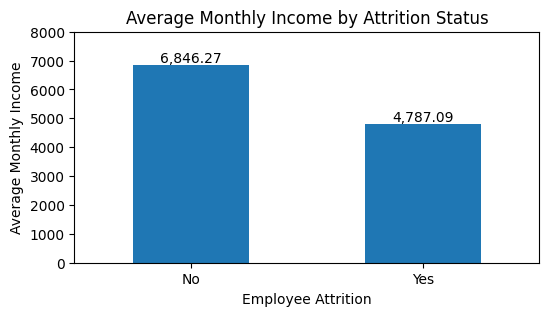

In [53]:
income_attrition = hr_data.groupby('Attrition')['MonthlyIncome'].mean()

ax = income_attrition.plot(
    kind='bar',
    figsize=(6, 3),
    title='Average Monthly Income by Attrition Status'
)

for i, value in enumerate(income_attrition):
    plt.text(i, value + 100, f'{value:,.2f}', ha='center')

plt.xlabel('Employee Attrition')
plt.ylabel('Average Monthly Income')
plt.xticks(rotation=0)
plt.ylim(0, 8000)
plt.show()

Observations – Average Monthly Income by Attrition Status

Employees who stayed (No) had an average monthly income of 6,846.27, compared with 4,787.09 for employees who left (Yes).

Employees who left earned approximately 30.08% less than those who stayed, representing a difference of 2,059.18 per month.

The findings suggest an association between lower monthly income and higher employee attrition. However, differences in job levels and job roles may also influence the results.

Conclusion:

In the Total Rewards framework, HR should also look into with compensation in terms of external competitiveness and internal pay equity, while recognising that financial rewards alone may not fully address employee retention challenges.

In [54]:
# Research Question 2.2 - Step 1
# Calculate average monthly income by job level

hr_data.groupby('JobLevel')['MonthlyIncome'].mean().round(2)

,MonthlyIncome
JobLevel,
1,2786.56
2,5506.04
3,9817.25
4,15503.78
5,19191.83


In [55]:
# Research Question 2.2 - Step 2
# Compare average monthly income by job level and attrition status

hr_data.groupby(['JobLevel', 'Attrition'])['MonthlyIncome'].mean().round(2)

JobLevel  Attrition
1         No            2854.43
          Yes           2598.13
2         No            5478.55
          Yes           5759.79
3         No            9891.03
          Yes           9388.41
4         No           15620.29
          Yes          13150.40
5         No           19170.58
          Yes          19463.80
Name: MonthlyIncome, dtype: float64

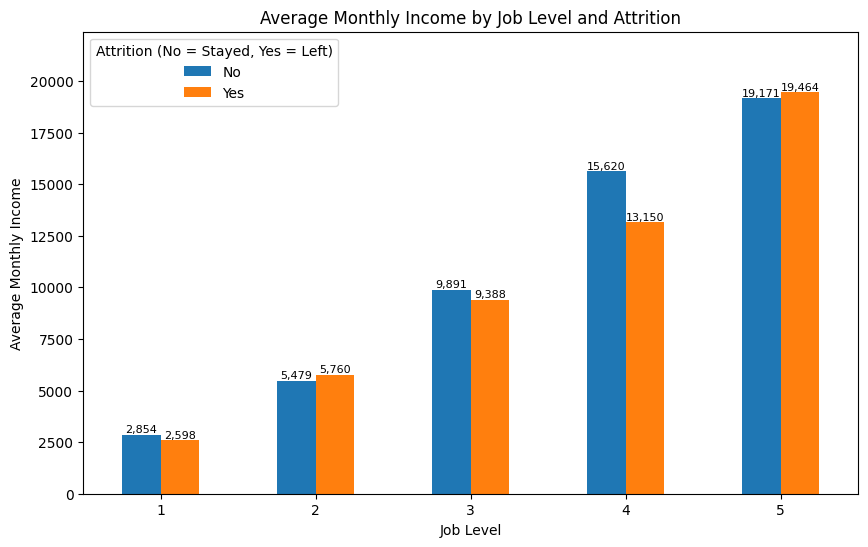

In [81]:
# RQ2.2 - Average Monthly Income by Job Level and Attrition

income_joblevel = hr_data.groupby(
    ['JobLevel', 'Attrition']
)['MonthlyIncome'].mean().unstack()

ax = income_joblevel.plot(
    kind='bar',
    figsize=(10, 6),
    title='Average Monthly Income by Job Level and Attrition'
)

# Display income above each bar
for bar in ax.patches:
    height = bar.get_height()
    if height == height:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + 100,
            f'{height:,.0f}',
            ha='center',
            fontsize=8
        )

plt.xlabel('Job Level')
plt.ylabel('Average Monthly Income')
plt.xticks(rotation=0)
plt.legend(title='Attrition (No = Stayed, Yes = Left)')
plt.ylim(0, income_joblevel.max().max() * 1.15)
plt.show()


Observations – Average Monthly Income by Job Level and Attrition

Average monthly income increases progressively from Job Level 1 to Job Level 5, reflecting higher remuneration at higher job levels.

At Job Levels 1, 3 and 4, employees who left earned less on average than those who stayed.

At Job Levels 2 and 5, employees who left actually earned slightly more than those who stayed.

The largest income difference was observed at Job Level 4, where employees who left earned 13,150, compared with 15,620 for employees who stayed, a difference of 2,470 (15.81%).

Conclusion:

The findings suggest that the relationship between compensation and employee attrition varies across job levels. Lower pay alone does not consistently explain employee departures.

In the Total Rewards framework, HR should also take into account both financial and non-financial factors to improve employee retention.

In [56]:
# Research Question 2.3
# Compare average percentage salary increase by attrition status
hr_data.groupby('Attrition')['PercentSalaryHike'].mean().round(2)


,PercentSalaryHike
Attrition,
No,15.23
Yes,15.10


**Stock options, tenure and marital-status context.**


In [57]:
# Research Question 2.4
# Count employees at each Stock Option Level

hr_data['StockOptionLevel'].value_counts().sort_index()


,count
StockOptionLevel,
0,629
1,593
2,158
3,85


In [58]:
# Research Question 2.5 - Step 1
# Calculate stock option percentages within each job level

for level in [1, 2, 3, 4, 5]:
    job_data = hr_data[hr_data['JobLevel'] == level]

    print("Job Level:", level)
    print((job_data['StockOptionLevel'].value_counts() / len(job_data) * 100).round(2))
    print()


Job Level: 1
StockOptionLevel
0    47.41
1    37.78
2     7.59
3     7.22
Name: count, dtype: float64

Job Level: 2
StockOptionLevel
0    40.98
1    38.72
2    15.60
3     4.70
Name: count, dtype: float64

Job Level: 3
StockOptionLevel
1    44.50
0    39.45
2    10.09
3     5.96
Name: count, dtype: float64

Job Level: 4
StockOptionLevel
1    46.23
0    40.57
2     7.55
3     5.66
Name: count, dtype: float64

Job Level: 5
StockOptionLevel
1    53.62
0    37.68
2     5.80
3     2.90
Name: count, dtype: float64



In [59]:
# Research Question 2.5 - Step 2
# Calculate average years of service by stock option level

hr_data.groupby('StockOptionLevel')['YearsAtCompany'].mean().round(2)


,YearsAtCompany
StockOptionLevel,
0,6.58
1,7.63
2,6.79
3,6.29


In [60]:
# Research Question 2.6
# Calculate attrition rate by stock option level

(hr_data.groupby('StockOptionLevel')['Attrition_Flag'].mean() * 100).round(2)

,Attrition_Flag
StockOptionLevel,
0,24.48
1,9.44
2,7.59
3,17.65


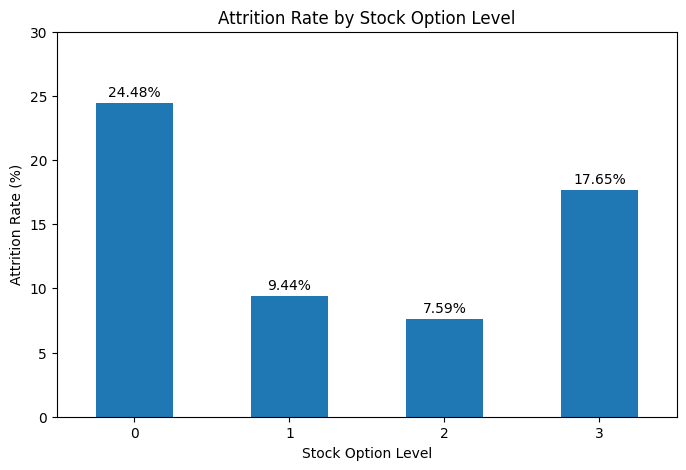

In [82]:
# RQ2.6 - Attrition Rate by Stock Option Level

stock_attrition = hr_data.groupby('StockOptionLevel')['Attrition_Flag'].mean() * 100

ax = stock_attrition.plot(
    kind='bar',
    figsize=(8, 5),
    title='Attrition Rate by Stock Option Level'
)

for i, value in enumerate(stock_attrition):
    plt.text(i, value + 0.5, f'{value:.2f}%', ha='center')

plt.xlabel('Stock Option Level')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=0)
plt.ylim(0, 30)
plt.show()


Observations – Attrition Rate by Stock Option Level

Level 0 recorded the highest attrition rate at 24.48%, while Level 2 had the lowest at 7.59%.

Attrition increased again at Level 3 at 17.65%, suggesting that higher stock options do not always correspond to lower attrition.

Conclusion: Long Term Incentives alone may not be sufficient to retain employees.


In [61]:
# Research Question 2.6 - Additional Analysis
# Examine stock option distribution by marital status

hr_data.groupby('MaritalStatus')['StockOptionLevel'].value_counts()

MaritalStatus  StockOptionLevel
Divorced       1                   195
               2                    75
               3                    49
               0                     8
Married        1                   398
               0                   153
               2                    83
               3                    36
Single         0                   468
Name: count, dtype: int64

In [62]:
# Research Question 2.6 - Additional Analysis Step 2
# Calculate attrition rate by marital status

(hr_data.groupby('MaritalStatus')['Attrition_Flag'].mean() * 100).round(2)


,Attrition_Flag
MaritalStatus,
Divorced,10.09
Married,12.54
Single,25.64


In [63]:
# Research Question 2.6 - Additional Analysis Step 3
# Calculate attrition rates by marital status and stock option level

(hr_data.groupby(['MaritalStatus', 'StockOptionLevel'])['Attrition_Flag'].mean() * 100).round(2)

MaritalStatus  StockOptionLevel
Divorced       0                   37.50
               1                    9.23
               2                    6.67
               3                   14.29
Married        0                   20.26
               1                    9.55
               2                    8.43
               3                   22.22
Single         0                   25.64
Name: Attrition_Flag, dtype: float64

**Key findings:** Leavers have lower average monthly income; average salary increases differ little by attrition status. Stock-option level is associated with attrition, but marital status affects the comparison. These are associations, not evidence of causation.


### RQ3. Are employees working overtime more likely to leave?
**Overtime patterns:** overall, by department and job role.


In [64]:
# Research Question 3.1
# Calculate attrition rate by overtime status

(hr_data.groupby('OverTime')['Attrition_Flag'].mean() * 100).round(2)


,Attrition_Flag
OverTime,
No,10.49
Yes,30.53


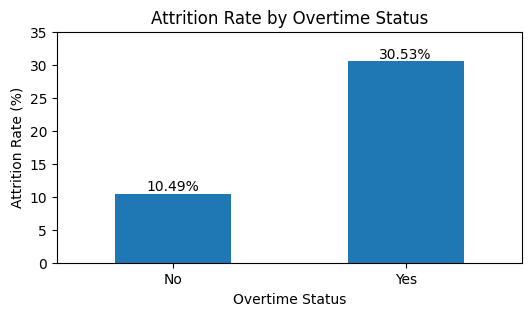

In [101]:
overtime_attrition = hr_data.groupby('OverTime')['Attrition_Flag'].mean() * 100
ax = overtime_attrition.plot(
    kind='bar',
    figsize=(6, 3
             ),
    title='Attrition Rate by Overtime Status'
)

# Display percentage above each bar
for i, value in enumerate(overtime_attrition):
    plt.text(i, value + 0.5, f'{value:.2f}%', ha='center')

plt.xlabel('Overtime Status')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=0)
plt.ylim(0, 35

         )
plt.show()

Observations - Attrition Rate by Overtime Status

Employees working overtime recorded an attrition rate of 30.53%, compared with 10.49% for employees not working overtime.

Attrition among overtime employees was nearly three times higher, suggesting a strong association between overtime and employee turnover.

Conclusion: In the Total Rewards framework, HR will need to pay attention to improve Work-Life Effectiveness.

In [65]:
# Research Question 3.2 - Step 1
# Calculate overtime attrition rates by department

(hr_data.groupby(['Department', 'OverTime'])['Attrition_Flag'].mean() * 100).round(2)


Department              OverTime
Human Resources         No          15.56
                        Yes         29.41
Research & Development  No           8.59
                        Yes         27.31
Sales                   No          13.88
                        Yes         37.50
Name: Attrition_Flag, dtype: float64

In [66]:
# Research Question 3.2 - Step 2
# Calculate overtime attrition rates by job role

(hr_data.groupby(['JobRole', 'OverTime'])['Attrition_Flag'].mean() * 100).round(2)


JobRole                    OverTime
Healthcare Representative  No           7.45
                           Yes          5.41
Human Resources            No          18.42
                           Yes         38.46
Laboratory Technician      No          15.90
                           Yes         50.00
Manager                    No           1.33
                           Yes         14.81
Manufacturing Director     No           5.66
                           Yes         10.26
Research Director          No           1.75
                           Yes          4.35
Research Scientist         No           7.22
                           Yes         34.02
Sales Executive            No          11.26
                           Yes         32.98
Sales Representative       No          28.81
                           Yes         66.67
Name: Attrition_Flag, dtype: float64

**Work-life balance among overtime employees.**


In [67]:
# Research Question 3.3
# Calculate attrition rates by work-life balance
# for employees working overtime

overtime_data = hr_data[hr_data['OverTime'] == 'Yes']

(overtime_data.groupby('WorkLifeBalance')['Attrition_Flag'].mean() * 100).round(2)

,Attrition_Flag
WorkLifeBalance,
1,45.45
2,30.77
3,28.74
4,33.33


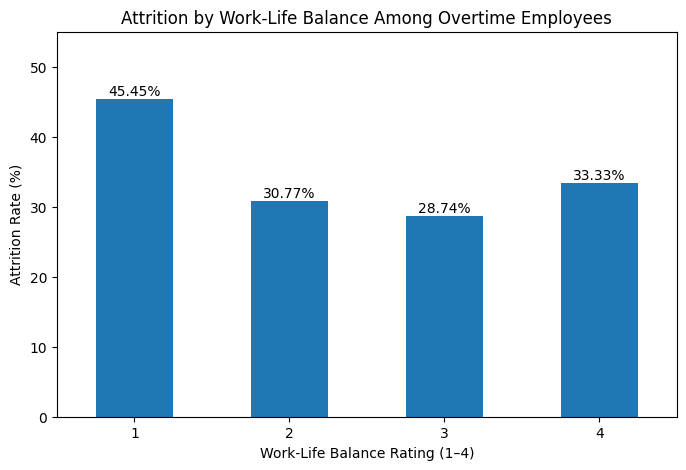

In [87]:
# RQ3 - Work-Life Balance and Attrition Among Overtime Employees

overtime_data = hr_data[hr_data['OverTime'] == 'Yes']

wlb_attrition = overtime_data.groupby('WorkLifeBalance')['Attrition_Flag'].mean() * 100

ax = wlb_attrition.plot(
    kind='bar',
    figsize=(8, 5),
    title='Attrition by Work-Life Balance Among Overtime Employees'
)

for i, value in enumerate(wlb_attrition):
    plt.text(i, value + 0.5, f'{value:.2f}%', ha='center')

plt.xlabel('Work-Life Balance Rating (1–4)')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=0)
plt.ylim(0, 55)
plt.show()

Observations - Attrition By Work-Life Effectiveness Among Overtime Employees

Among employees working overtime, those with Work-Life Effectiveness Rating 1 recorded the highest attrition rate (45.45%).

Attrition was lowest at Rating 3 (28.74%), but increased again at Rating 4 (33.33%).

This suggests that poorer work-life balance is associated with higher attrition, although the pattern is not consistent across all ratings.

Conclusion: HR should adopt a holistic Total Rewards framework, with particular emphasis on Work-Life Effectiveness to improve employee retention.

In [68]:
# Research Question 3.3 - Additional Analysis
# Count employees who stayed and left by work-life balance

overtime_data.groupby('WorkLifeBalance')['Attrition'].value_counts()

WorkLifeBalance  Attrition
1                No            12
                 Yes           10
2                No            72
                 Yes           32
3                No           181
                 Yes           73
4                No            24
                 Yes           12
Name: count, dtype: int64

**Key findings:** Overtime employees have a higher attrition rate (30.53%) than non-overtime employees (10.49%). Poor work-life balance is associated with higher attrition among overtime employees; small rating groups require caution.


### RQ4. How do satisfaction and job involvement relate to attrition?


In [69]:
# Research Question 4.1
# Calculate attrition rate by job satisfaction level

(hr_data.groupby('JobSatisfaction')['Attrition_Flag'].mean() * 100).round(2)

,Attrition_Flag
JobSatisfaction,
1,22.92
2,16.49
3,16.59
4,11.35


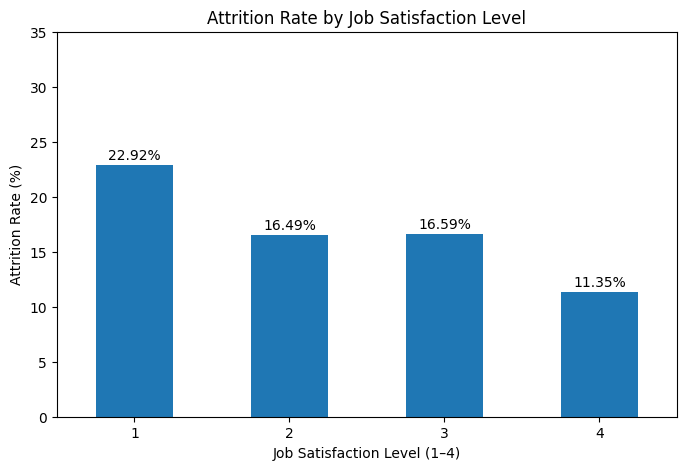

In [92]:
job_satisfaction_attrition = hr_data.groupby('JobSatisfaction')['Attrition_Flag'].mean() * 100
ax = job_satisfaction_attrition.plot(
    kind='bar',
    figsize=(8, 5),
    title='Attrition Rate by Job Satisfaction Level'
)

for i, value in enumerate(job_satisfaction_attrition):
    plt.text(i, value + 0.5, f'{value:.2f}%', ha='center')

plt.xlabel('Job Satisfaction Level (1–4)')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=0)
plt.ylim(0, 35)
plt.show()


Observations - Attrition Rate By Job Satisfaction Level

Employees with Job Satisfaction Level 1 recorded the highest attrition rate at 22.92%.

Employees with Level 4 recorded the lowest attrition rate at 11.35%.

Overall, higher job satisfaction is associated with lower employee attrition.

Conclusion: In the Total Rewards framework, HR should also focus on employee recognition and talent management to improve retention.

In [70]:
# Research Question 4.2
# Calculate attrition rate by environment satisfaction level

(hr_data.groupby('EnvironmentSatisfaction')['Attrition_Flag'].mean() * 100).round(2)


,Attrition_Flag
EnvironmentSatisfaction,
1,25.35
2,14.98
3,13.75
4,13.54


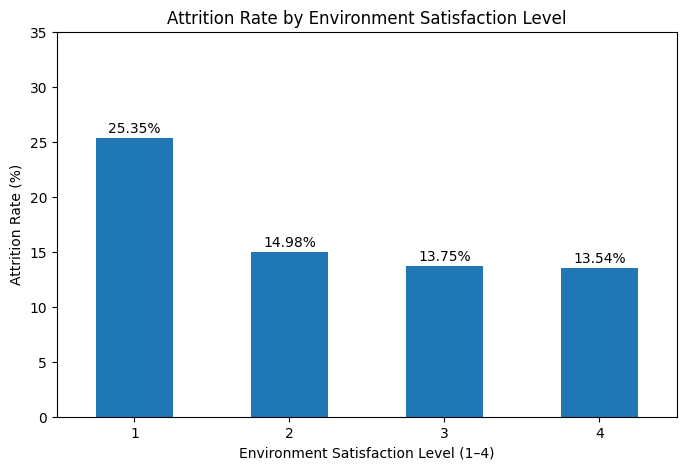

In [90]:
# RQ4.2 - Attrition Rate by Environment Satisfaction

environment_attrition = hr_data.groupby('EnvironmentSatisfaction')['Attrition_Flag'].mean() * 100

ax = environment_attrition.plot(
    kind='bar',
    figsize=(8, 5),
    title='Attrition Rate by Environment Satisfaction Level'
)

for i, value in enumerate(environment_attrition):
    plt.text(i, value + 0.5, f'{value:.2f}%', ha='center')

plt.xlabel('Environment Satisfaction Level (1–4)')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=0)
plt.ylim(0, 35)
plt.show()


Observations - Attrition Rate by Environment Satisfaction


Employees with Environment Satisfaction Level 1 has the highest attrition rate at 25.35%.

Attrition decreased as satisfaction improved, reaching the lowest rate at Level 4 at 13.54%.

This indicate that a less satisfactory working environment is associated with higher employee attrition.

Conclusion: Work-Life Effectiveness and Recognition are one of the factors to improve on employee satisfaction and retention.

In [71]:
# Research Question 4.3
# Calculate attrition rate by job involvement level

(hr_data.groupby('JobInvolvement')['Attrition_Flag'].mean() * 100).round(2)


,Attrition_Flag
JobInvolvement,
1,33.73
2,18.98
3,14.47
4,9.03


In [72]:
# Research Question 4.4
# Compare attrition rates across three indicators

for indicator in ['JobSatisfaction', 'EnvironmentSatisfaction', 'JobInvolvement']:
    print(indicator)
    print((hr_data.groupby(indicator)['Attrition_Flag'].mean() * 100).round(2))
    print()

JobSatisfaction
JobSatisfaction
1    22.92
2    16.49
3    16.59
4    11.35
Name: Attrition_Flag, dtype: float64

EnvironmentSatisfaction
EnvironmentSatisfaction
1    25.35
2    14.98
3    13.75
4    13.54
Name: Attrition_Flag, dtype: float64

JobInvolvement
JobInvolvement
1    33.73
2    18.98
3    14.47
4     9.03
Name: Attrition_Flag, dtype: float64



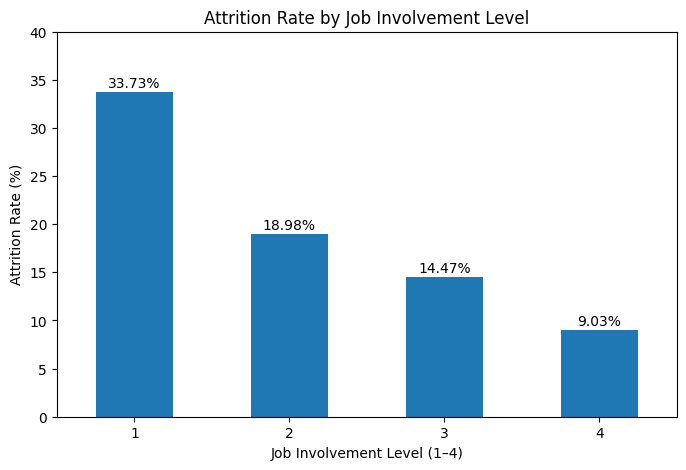

In [102]:
involvement_attrition = hr_data.groupby('JobInvolvement')['Attrition_Flag'].mean() * 100
ax = involvement_attrition.plot(
    kind='bar',
    figsize=(8, 5),
    title='Attrition Rate by Job Involvement Level'
)

for i, value in enumerate(involvement_attrition):
    plt.text(i, value + 0.5, f'{value:.2f}%', ha='center')

plt.xlabel('Job Involvement Level (1–4)')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=0)
plt.ylim(0, 40)
plt.show()

**Key findings:** Lower job satisfaction, environment satisfaction and job involvement are associated with higher attrition. Job involvement has the largest observed rating-1-to-4 gap (24.70 percentage points); this does not establish an independent or causal effect.


###RQ5. How are employee performance, career progression and salary growth associated with employee attrition?


In [73]:
# RQ5.1: Attrition rate by years since last promotion
# To determine whether employees who have longer wait for promotion have higher attrition rates.
(hr_data.groupby('YearsSinceLastPromotion')['Attrition_Flag'].mean() * 100).round(2)

,Attrition_Flag
YearsSinceLastPromotion,
0,18.97
1,13.73
2,17.09
3,17.65
4,8.33
5,4.55
6,18.75
7,21.05
8,0.00


In [74]:
# Check number of employees by years since last promotion

hr_data.groupby('YearsSinceLastPromotion')['Attrition'].value_counts()

YearsSinceLastPromotion  Attrition
0                        No           470
                         Yes          110
1                        No           308
                         Yes           49
2                        No           131
                         Yes           27
3                        No            42
                         Yes            9
4                        No            55
                         Yes            5
5                        No            42
                         Yes            2
6                        No            26
                         Yes            6
7                        No            60
                         Yes           16
8                        No            18
9                        No            13
                         Yes            4
10                       No             5
                         Yes            1
11                       No            22
                         Yes            2
12                       No            10
13                       No             8
                         Yes            2
14                       No             8
                         Yes            1
15                       No            10
                         Yes            3
Name: count, dtype: int64

####Findings : Attrition rates fluctuate across the years with no consistent increasing trend. Although some employees with longer periods without promotion have higher attrition rates, these groups contain relatively few employees. Therefore, the results do not provide clear evidence that longer periods without promotion are consistently associated with higher employee attrition.  From a HR perspective normally lack of promotion may contribute to employee turnover, but our results do not show a relationship between these two elements.

In [75]:
# RQ5.2: Average years since last promotion by performance rating

hr_data.groupby('PerformanceRating')['YearsSinceLastPromotion'].mean().round(2)

,YearsSinceLastPromotion
PerformanceRating,
3,2.16
4,2.31


####Findings
- Rating 3: Average promotion is 2.16 years.
- Rating 4: Average promotion is 2.31 years.

This means higher-performing employees have not necessarily received more recent promotions.

In [76]:
# RQ5.3: Average salary increase by performance rating
# To examine whether employees with higher performance ratings receive higher percentage salary increases.
hr_data.groupby('PerformanceRating')['PercentSalaryHike'].mean().round(2)


,PercentSalaryHike
PerformanceRating,
3,14.01
4,21.84


Findings: Outstanding performers receive an average salary increase of 21.84%, compared with 14.01% for top performers. This is a difference of 7.83 percentage points.

Conclusion: The results indicate that salary increases are differentiated according to performance, a pay for performance approach.

In [77]:
# RQ5.4A: Attrition rate by years of service

(hr_data.groupby('YearsAtCompany')['Attrition_Flag'].mean() * 100).round(2)


,Attrition_Flag
YearsAtCompany,
0,36.36
1,34.50
2,21.43
3,15.62
4,17.27
5,10.71
6,12.00
7,12.36
8,11.39


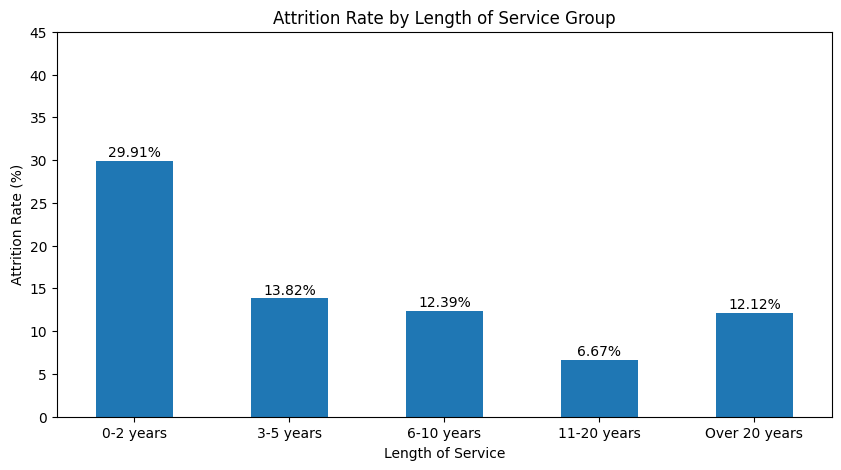

In [97]:
 ##RQ5.4 - Attrition Rate by Length of Service Groups

hr_data['ServiceGroup'] = pd.cut(
    hr_data['YearsAtCompany'],
    bins=[-1, 2, 5, 10, 20, 100],
    labels=['0-2 years', '3-5 years', '6-10 years',
            '11-20 years', 'Over 20 years']
)

service_attrition = hr_data.groupby('ServiceGroup', observed=True)['Attrition_Flag'].mean() * 100

ax = service_attrition.plot(
    kind='bar',
    figsize=(10, 5),
    title='Attrition Rate by Length of Service Group'
)

for i, value in enumerate(service_attrition):
    plt.text(i, value + 0.5, f'{value:.2f}%', ha='center')

plt.xlabel('Length of Service')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=0)
plt.ylim(0, 45)
plt.show()



Observations - Attrition Rate By Length Of Service

Employees with 0–2 years of service recorded the highest attrition rate (29.91%), accounting for 43.04% of total departures.

Attrition declined with longer service, reaching its lowest at 11–20 years (6.67%).

Attrition increased again to 12.12% among employees with over 20 years of service.

Conclusion: HR should adopt a holistic Total Rewards framework, with particular emphasis on Talent Management, including onboarding, career development and retention of new employees.

In [98]:
# RQ5.5 - Count Employees by Years of Service Group

service_count = hr_data.groupby('ServiceGroup', observed=True)['Attrition'].value_counts().unstack(fill_value=0)

service_count['Total'] = service_count['No'] + service_count['Yes']

service_count

Attrition,No,Yes,Total
ServiceGroup,,,
0-2 years,239,102,341
3-5 years,374,60,434
6-10 years,389,55,444
11-20 years,168,12,180
Over 20 years,58,8,66


Findings : Employee attrition is highest among employees in their first two years of service, particularly those with 0–1 year of tenure. Attrition generally decreases as employees gain experience with the organisation. Although some long-serving groups show high attrition rates, their small employee numbers make these percentages less reliable.

In [79]:
# Attrition count by performance rating
hr_data.groupby('PerformanceRating')['Attrition'].value_counts()


PerformanceRating  Attrition
3                  No           1040
                   Yes           200
4                  No            188
                   Yes            37
Name: count, dtype: int64

Despite receiving a higher average salary increase:
- Excellent performers: 14.01% salary increase
- Outstanding performers: 21.84% salary increase
Both groups have almost identical attrition rates of approximately 16%.

HR Perspective : Higher salary increases alone do not guarantee retention, even among outstanding performers.

In [80]:
#R5.5 Attrition count and rate by performance rating

result = hr_data.groupby('PerformanceRating')['Attrition'].value_counts().unstack(fill_value=0)

result['Total'] = result['No'] + result['Yes']
result['Attrition Rate (%)'] = (result['Yes'] / result['Total'] * 100).round(2)

result


Attrition,No,Yes,Total,Attrition Rate (%)
PerformanceRating,,,,
3,1040,200,1240,16.13
4,188,37,225,16.44
